In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults
from qss.chemical_potential import chemical_potential
from qss.entropy import entropy
from qss.distributions import prepare_2D_lattice_data, DistType
import tools.scientific_plot_v2 as sp
plotter = sp.ScientificPlotter()

## 2D Lattice

In [2]:
N = 100
t = -1
# t_prim = 0.25
t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Chemical Potential (n)

In [3]:
# Band filling values
n_min = 0.01
n_max = 0.99
n_count = 40

kBT = [10, 1, 0.01]
H_a = [0.]
U = 1.0


distros = [DistType.FD, DistType.FLB, DistType.NFL, DistType.NFLB, DistType.SSL, DistType.HUBBARD]  # ND
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
kBT = np.array(kBT, dtype=np.float64)  # NB
H_a = np.array(H_a, dtype=np.float64) # NH

In [4]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=2.0,
    initial_step=1.0,  
    max_expands=164,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

mu_df = chemical_potential(
    distros=distros,
    n_vals=n,
    kBT_vals=kBT,
    H_a_vals=H_a,
    N=N,
    E=e_k,
    solver_opts=native_opts,
    x0=-1.0,
    a0=-5.0,
    b0=5.0,
)


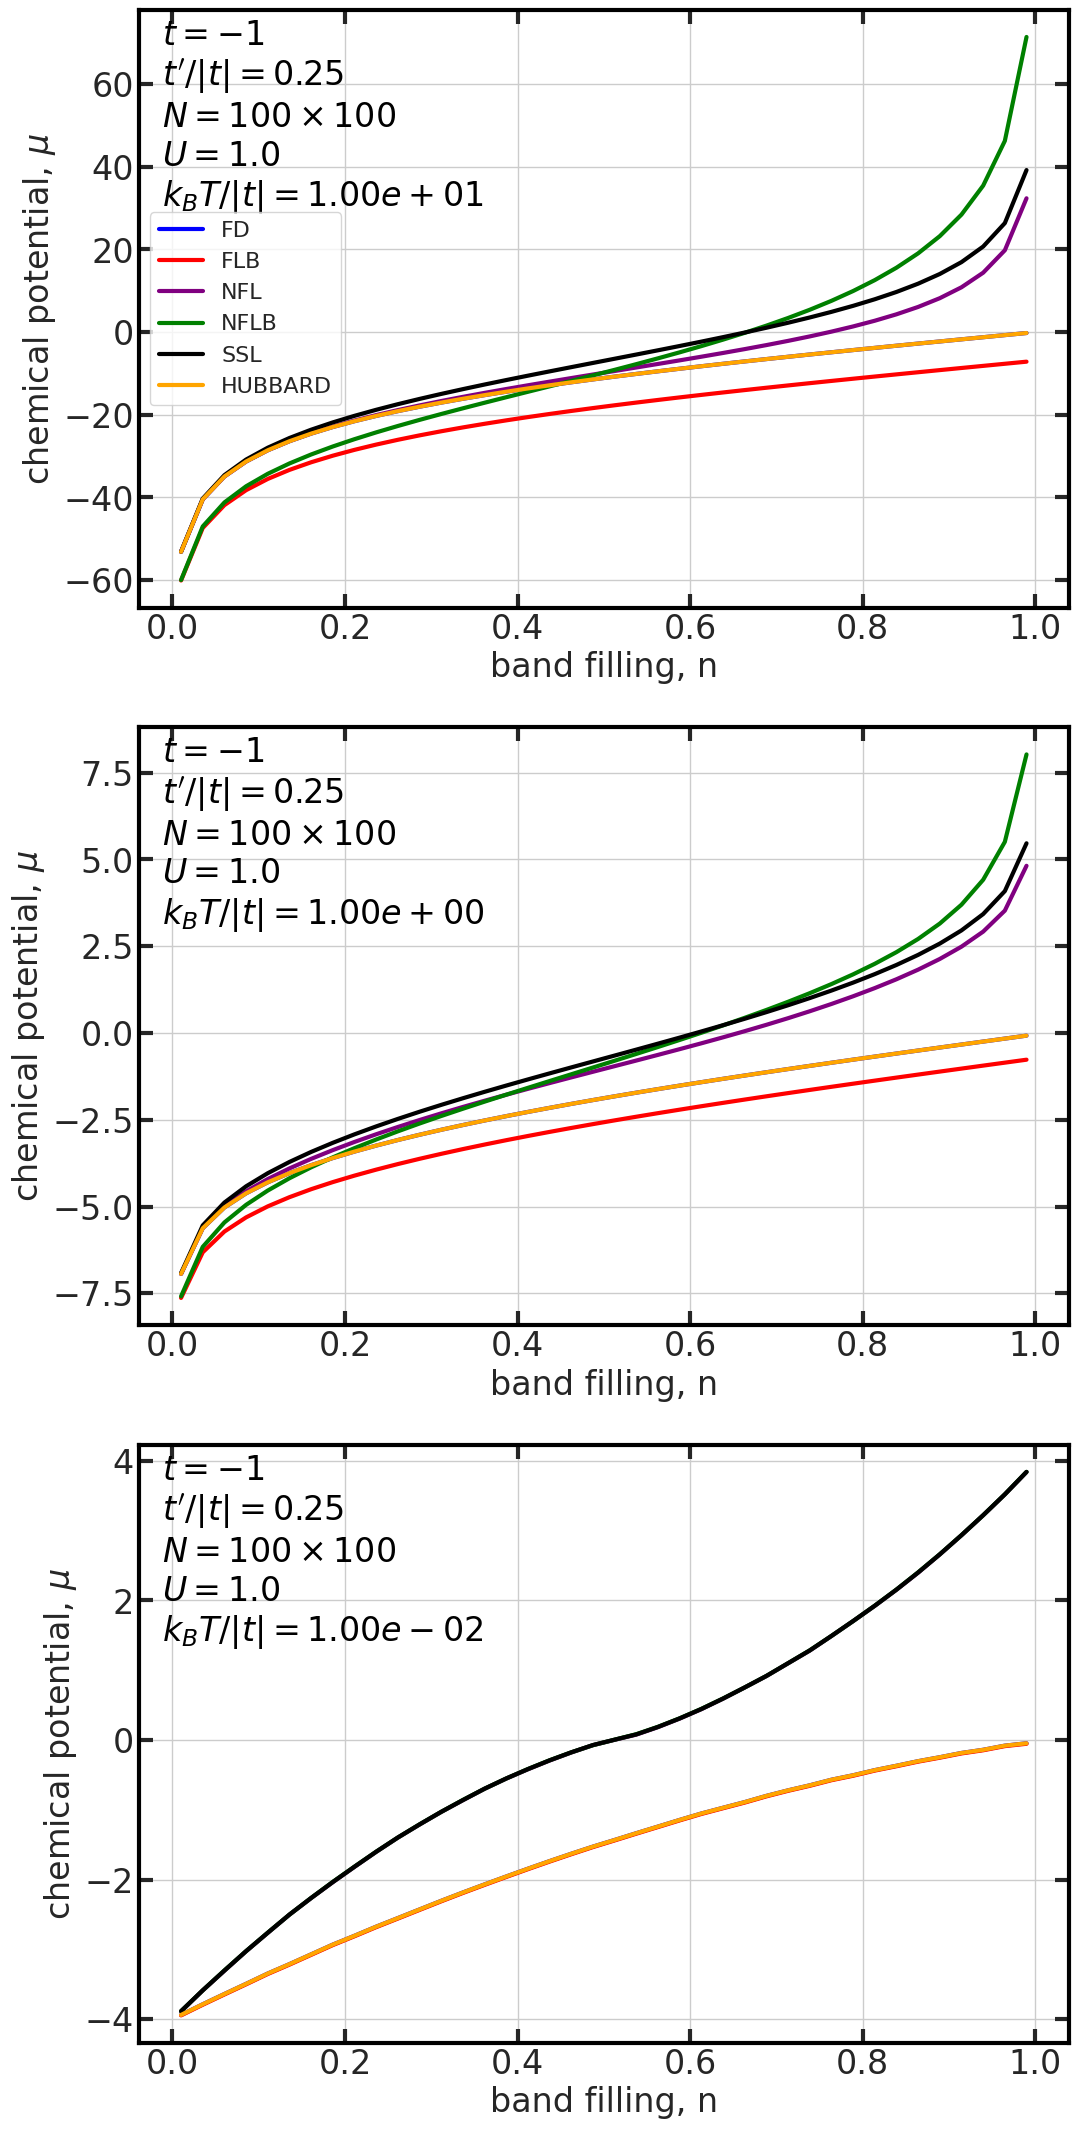

In [5]:
H_a_plot = H_a[0] 
distro = ["FD","FLB","NFL", "NFLB", "SSL", "HUBBARD"]
# Plot
legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=mu_df,
    x_param="n",
    y_col="mu",
    y_label=r"chemical potential, $\mu$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="kBT",
    subplots_vals=kBT,
    cols=1,
    U = U,
    figsize=(12, 8.8),
    # xscale="log",
    # ylims=(-2, 10),
    # xlims=(0.01, 1)
)
plt.show()


## Chemical Potential (T)

In [6]:
# Band filling values
n = [0.8, 0.99]
H_a = [0]

# Temperature values (kBT)
kBT_min = 1e-3
kBT_max = 1.0
kBT_count = 40

U = 1.0

distros = [DistType.FD, DistType.FLB, DistType.NFL, DistType.NFLB, DistType.SSL, DistType.HUBBARD]  # ND
n  = np.array(n, dtype=np.float64)  # NN
kBT = np.logspace(np.log10(kBT_min), np.log10(kBT_max), kBT_count, dtype=np.float64)  # NB
H_a = np.array(H_a, dtype=np.float64) # NH

In [7]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=2.0,
    initial_step=1.0,  
    max_expands=164,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

mu_df = chemical_potential(
    distros=distros,
    n_vals=n,
    kBT_vals=kBT,
    H_a_vals=H_a,
    N=N,
    E=e_k,
    solver_opts=native_opts,
    x0=-1.0,
    a0=-5.0,
    b0=5.0,
)


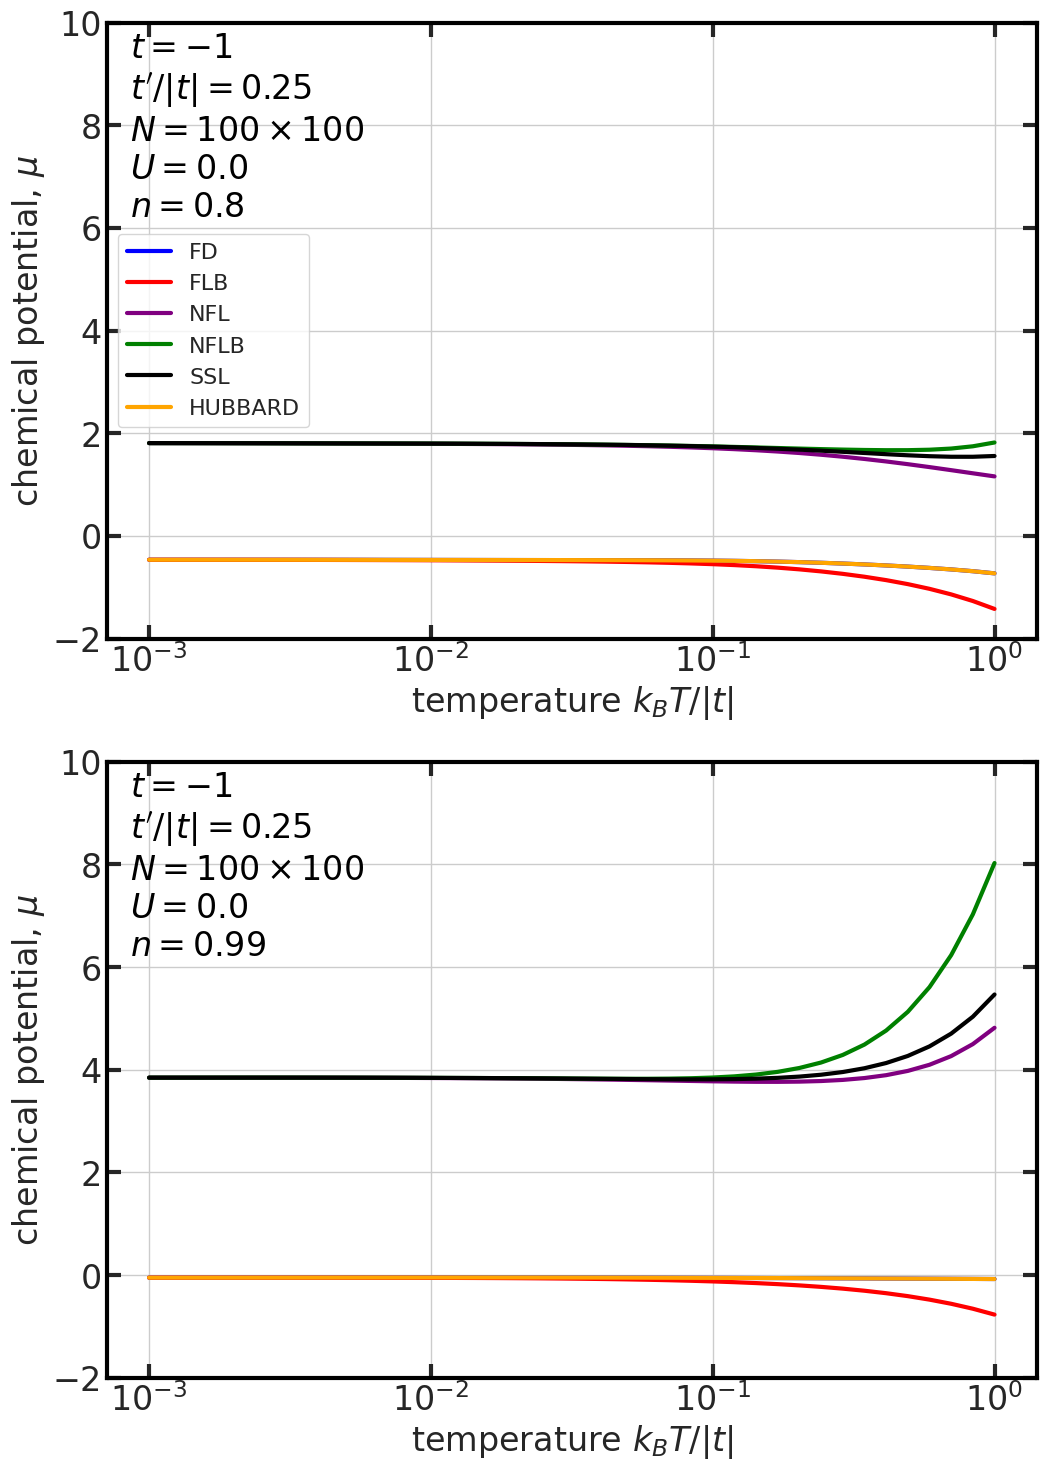

In [8]:
H_a_plot = H_a[0] 
distro = ["FD","FLB","NFL", "NFLB", "SSL", "HUBBARD"]
# Plot
legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=mu_df,
    x_param="k_BT",
    y_col="mu",
    y_label=r"chemical potential, $\mu$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="n",
    subplots_vals=n,
    cols=1,
    figsize=(12, 8.8),
    xscale="log",
    ylims=(-2, 10),
    # xlims=(0.01, 1)
)
plt.show()
